# 03. Modeling — diagnostyka szeregu i porównanie modeli



Cel: Zbadanie dziennej sprzedaży sklepu Rossmann, przeprowadzenie diagnostyki szeregu czasowego oraz porównanie modeli w horyzoncie 30 dni  zgodnie z protokołem rolling one-step-ahead forecasting. W rolling one-step-ahead rzeczywiste Sales(t-1) jest dostępne podczas prognozowania dnia t.

Jednostka prognozy: pojedynczy sklep i dzień (Store–Date).

Zmienna docelowa: Sales.

Dni zamknięcia: prognoza sprzedaży wynosi 0, a metryki modeli sprzedaży liczymy wyłącznie dla dni z Open = 1.

Walidacja: pięć kolejnych, rozszerzających się okien treningowych i 30-dniowych okien walidacyjnych. Końcowy okres testowy pozostaje poza walidacją i doborem parametrów.

In [88]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf

from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
warnings.filterwarnings("ignore", category=FutureWarning)

try:
    import tensorflow as tf
    from tensorflow import keras
    from tensorflow.keras import layers
    TF_AVAILABLE = True
    tf.keras.utils.set_random_seed(RANDOM_STATE)
except ModuleNotFoundError:
    tf = keras = layers = None
    TF_AVAILABLE = False

In [47]:
current_dir = Path.cwd().resolve()
PROJECT_ROOT = next(
    (p for p in (current_dir, *current_dir.parents)
     if (p / "data" / "processed" / "features.parquet").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Nie znaleziono data/processed/features.parquet. "
        
    )
DATA_DIR = PROJECT_ROOT / "data" / "processed"
OUTPUT_DIR = PROJECT_ROOT / "reports" / "modeling"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

features_df = pd.read_parquet(DATA_DIR / "features.parquet")
features_df["Date"] = pd.to_datetime(features_df["Date"])
features_df = features_df.sort_values(["Store", "Date"]).reset_index(drop=True)

print("Shape:", features_df.shape)
print("Stores:", features_df["Store"].nunique())
print("Date range:", features_df["Date"].min().date(), "—", features_df["Date"].max().date())
display(features_df.head())

Shape: (1017209, 42)
Stores: 1115
Date range: 2013-01-01 — 2015-07-31


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,...,Sales_lag_1,Sales_lag_7,Sales_lag_14,Sales_lag_28,Sales_roll_mean_7,Sales_roll_std_7,Sales_roll_mean_14,Sales_roll_std_14,Sales_roll_mean_28,Sales_roll_std_28
0,1,2,2013-01-01,0,0,0,0,a,1,c,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,3,2013-01-02,5530,668,1,0,0,1,c,...,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1,4,2013-01-03,4327,578,1,0,0,1,c,...,5530.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1,5,2013-01-04,4486,619,1,0,0,1,c,...,4327.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1,6,2013-01-05,4997,635,1,0,0,1,c,...,4486.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [48]:
# Modeling configuration
HORIZON = 30
N_SPLITS = 5
TARGET = "Sales"
STORE_ID = 1

In [49]:
store_data = (
    features_df.loc[features_df["Store"].eq(STORE_ID)]
    .sort_values("Date")
    .copy()
)
if store_data.empty:
    raise ValueError(f"Brak danych dla Store={STORE_ID}")
if store_data["Date"].duplicated().any():
    raise ValueError("Historia zawiera zduplikowane daty.")

store_data["Date"] = pd.to_datetime(store_data["Date"])
store_data = store_data.set_index("Date").sort_index()

print(f"Store: {STORE_ID}")
print(f"History: {store_data.index.min().date()} — {store_data.index.max().date()}")
print("Observations:", len(store_data))
print("Missing Sales:", int(store_data[TARGET].isna().sum()))
print("Missing dates in calendar:", len(
    pd.date_range(store_data.index.min(), store_data.index.max(), freq="D")
    .difference(store_data.index)
))
display(store_data[["Store", TARGET, "Open"]].head())

Store: 1
History: 2013-01-01 — 2015-07-31
Observations: 942
Missing Sales: 0
Missing dates in calendar: 0


,Store,Sales,Open
Date,,,
2013-01-01,1,0,0
2013-01-02,1,5530,1
2013-01-03,1,4327,1
2013-01-04,1,4486,1
2013-01-05,1,4997,1


## Chronologiczny podział train / validation / test

Ostatnie 30 dni stanowi TEST, poprzedzające je 30 dni — VALIDATION, a wcześniejsze obserwacje — TRAIN. W każdej części prognozujemy kolejny dzień, a nie cały okres z jednego punktu startowego.

,split,start,end,n
0,TRAIN,2013-01-01,2015-06-01,882
1,VALIDATION,2015-06-02,2015-07-01,30
2,TEST,2015-07-02,2015-07-31,30


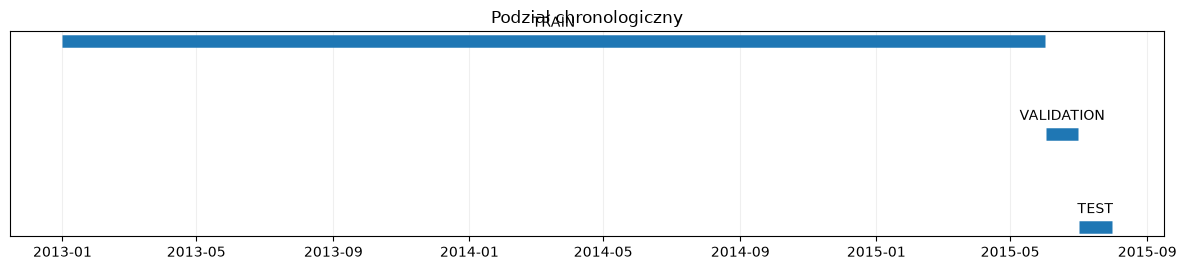

In [106]:
max_date = store_data.index.max()
test_start = max_date - pd.Timedelta(days=HORIZON - 1)
validation_end = test_start - pd.Timedelta(days=1)
validation_start = validation_end - pd.Timedelta(days=HORIZON - 1)
train_end = validation_start - pd.Timedelta(days=1)

train_data = store_data.loc[:train_end].copy()
train_series = train_data[TARGET].dropna().astype(float)
validation_series = validation_data[TARGET].dropna().astype(float)
validation_data = store_data.loc[validation_start:validation_end].copy()
test_data = store_data.loc[test_start:max_date].copy()

split_summary = pd.DataFrame([
    {"split": "TRAIN", "start": train_data.index.min(), "end": train_data.index.max(), "n": len(train_data)},
    {"split": "VALIDATION", "start": validation_data.index.min(), "end": validation_data.index.max(), "n": len(validation_data)},
    {"split": "TEST", "start": test_data.index.min(), "end": test_data.index.max(), "n": len(test_data)},
])
display(split_summary)
assert train_data.index.max() < validation_data.index.min()
assert validation_data.index.max() < test_data.index.min()
assert len(validation_data) == HORIZON and len(test_data) == HORIZON

fig, ax = plt.subplots(figsize=(12, 2.8))
for label, start, end, y in [
    ("TRAIN", train_data.index.min(), train_data.index.max(), 2),
    ("VALIDATION", validation_data.index.min(), validation_data.index.max(), 1),
    ("TEST", test_data.index.min(), test_data.index.max(), 0),
]:
    ax.hlines(y, start, end, linewidth=9)
    ax.text(start + (end-start)/2, y+0.15, label, ha="center")
ax.set_yticks([])
ax.set_title("Podział chronologiczny")
ax.grid(alpha=0.2, axis="x")
plt.tight_layout()
plt.show()



## 3. Wizualna diagnostyka, trend i sezonowość

Eksplorację i dekompozycję wykonujemy wyłącznie na TRAIN. Porównujemy okresy sezonowe 7 i 365 dni

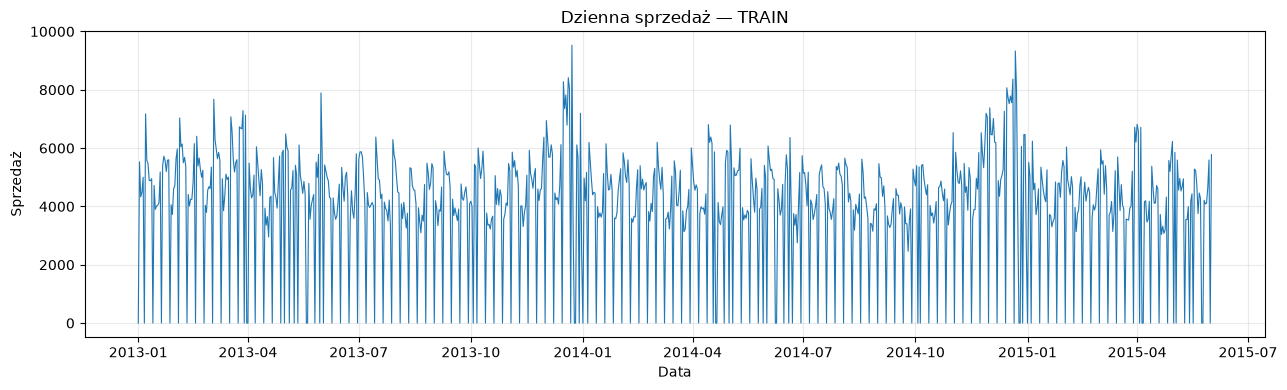

In [26]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(train_series.index, train_series.values, linewidth=0.8)
ax.set_title("Dzienna sprzedaż — TRAIN")
ax.set_xlabel("Data")
ax.set_ylabel("Sprzedaż")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

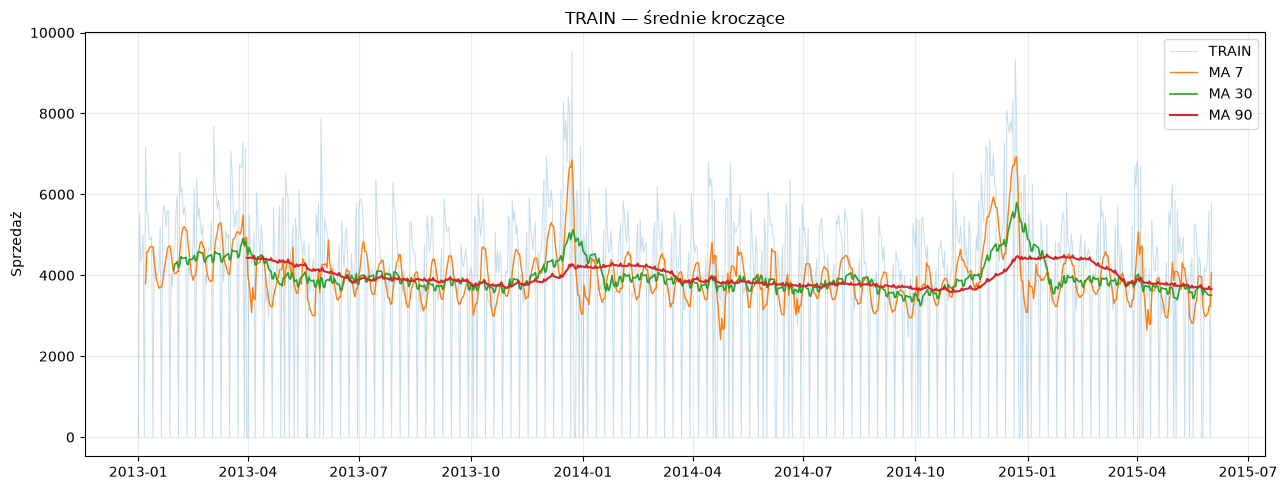

In [27]:
rolling_7 = train_series.rolling(7).mean()
rolling_30 = train_series.rolling(30).mean()
rolling_90 = train_series.rolling(90).mean()

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(train_series.index, train_series.values, alpha=0.25, linewidth=0.7, label="TRAIN")
ax.plot(rolling_7.index, rolling_7, linewidth=1.0, label="MA 7")
ax.plot(rolling_30.index, rolling_30, linewidth=1.2, label="MA 30")
ax.plot(rolling_90.index, rolling_90, linewidth=1.5, label="MA 90")
ax.set_title("TRAIN — średnie kroczące")
ax.set_ylabel("Sprzedaż")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [28]:
def run_decomposition(series, period):
    result = seasonal_decompose(series, model="additive", period=period)

    fig, axes = plt.subplots(4, 1, figsize=(13, 9), sharex=True)
    panels = [
        ("Observed", result.observed),
        ("Trend", result.trend),
        (f"Seasonal | period={period}", result.seasonal),
        ("Residual", result.resid),
    ]
    for ax, (title, values) in zip(axes, panels):
        ax.plot(values)
        ax.set_title(title)
        ax.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()
    return result

In [29]:
DECOMPOSITION_PERIOD = 365

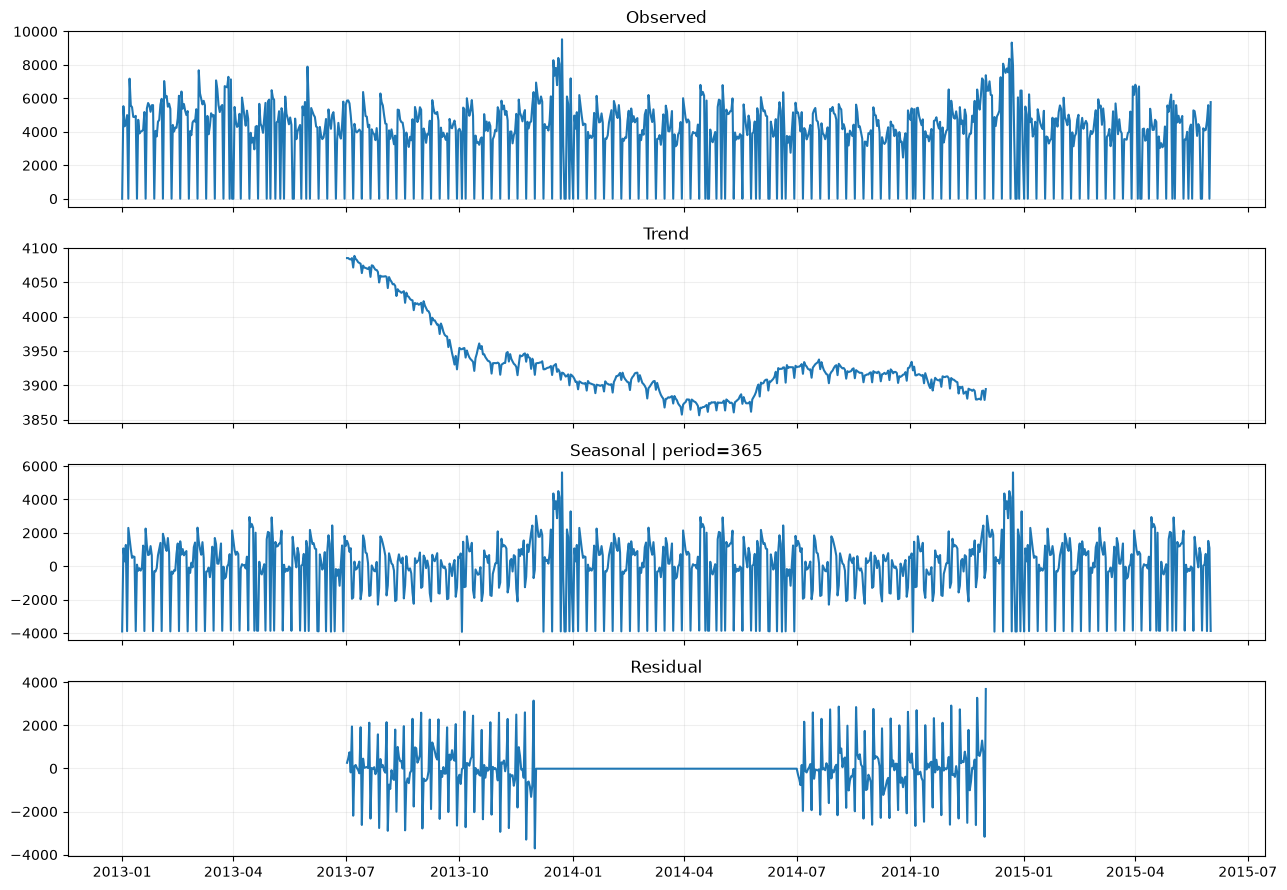

In [30]:
decomposition = run_decomposition(train_series, period=DECOMPOSITION_PERIOD)

Wykonamy  eksperyment dekompozycji szeregu czasowego na podstawie średniej  sprzedaży. Przy obliczaniu średniej uwzględnimy wyłącznie te sklepy, dla których dostępne są kompletne dane za okres od 2014-07-01 do 2014-12-31.

In [51]:
# Define the validation period
start_date = pd.Timestamp("2014-07-01")
end_date = pd.Timestamp("2014-12-31")

# Use the original sales dataset, before filtering Sales > 0
sales_data = features_df [["Store", "Date", "Sales"]].copy()

sales_data["Date"] = pd.to_datetime(sales_data["Date"])

# Select observations within the validation period
period_data = sales_data.loc[
    sales_data["Date"].between(start_date, end_date)
].copy()

# Expected number of calendar days: 184
expected_days = len(pd.date_range(start_date, end_date, freq="D"))

# Count distinct dates available for each store
store_date_counts = period_data.groupby("Store")["Date"].nunique()

# Keep only stores with data for every day in the period
complete_stores = store_date_counts[
    store_date_counts == expected_days
].index

print(f"Expected days: {expected_days}")
print(f"Stores in the dataset: {sales_data['Store'].nunique()}")
print(f"Stores with complete data: {len(complete_stores)}")
print(
    f"Excluded stores: "
    f"{sales_data['Store'].nunique() - len(complete_stores)}"
)

Expected days: 184
Stores in the dataset: 1115
Stores with complete data: 935
Excluded stores: 180


In [52]:
# Keep only stores with complete data in the validation period
filtered_sales = sales_data.loc[
    sales_data["Store"].isin(complete_stores)
].copy()

# Calculate average daily sales across eligible stores
daily_avg_sales = (
    filtered_sales
    .groupby("Date")["Sales"]
    .mean()
    .sort_index()
    .asfreq("D")
)

print(f"Analysis period: {daily_avg_sales.index.min()} — "
      f"{daily_avg_sales.index.max()}")
print(f"Number of daily observations: {len(daily_avg_sales)}")
print(f"Missing daily values: {daily_avg_sales.isna().sum()}")

Analysis period: 2013-01-01 00:00:00 — 2015-07-31 00:00:00
Number of daily observations: 942
Missing daily values: 0


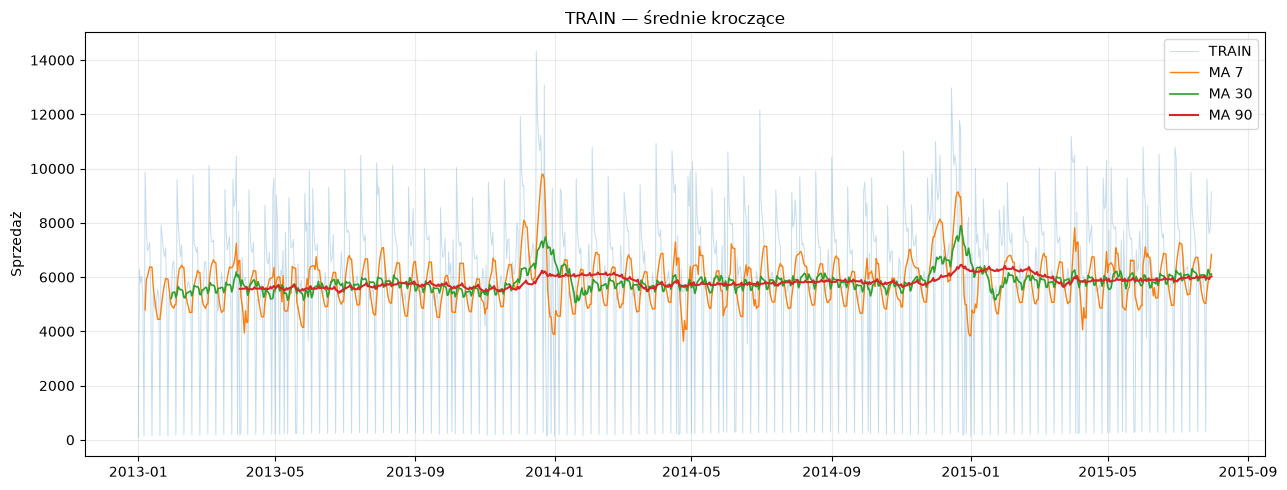

In [53]:
rolling_7 = daily_avg_sales.rolling(7).mean()
rolling_30 = daily_avg_sales.rolling(30).mean()
rolling_90 = daily_avg_sales.rolling(90).mean()

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(daily_avg_sales.index, daily_avg_sales.values, alpha=0.25, linewidth=0.7, label="TRAIN")
ax.plot(rolling_7.index, rolling_7, linewidth=1.0, label="MA 7")
ax.plot(rolling_30.index, rolling_30, linewidth=1.2, label="MA 30")
ax.plot(rolling_90.index, rolling_90, linewidth=1.5, label="MA 90")
ax.set_title("TRAIN — średnie kroczące")
ax.set_ylabel("Sprzedaż")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

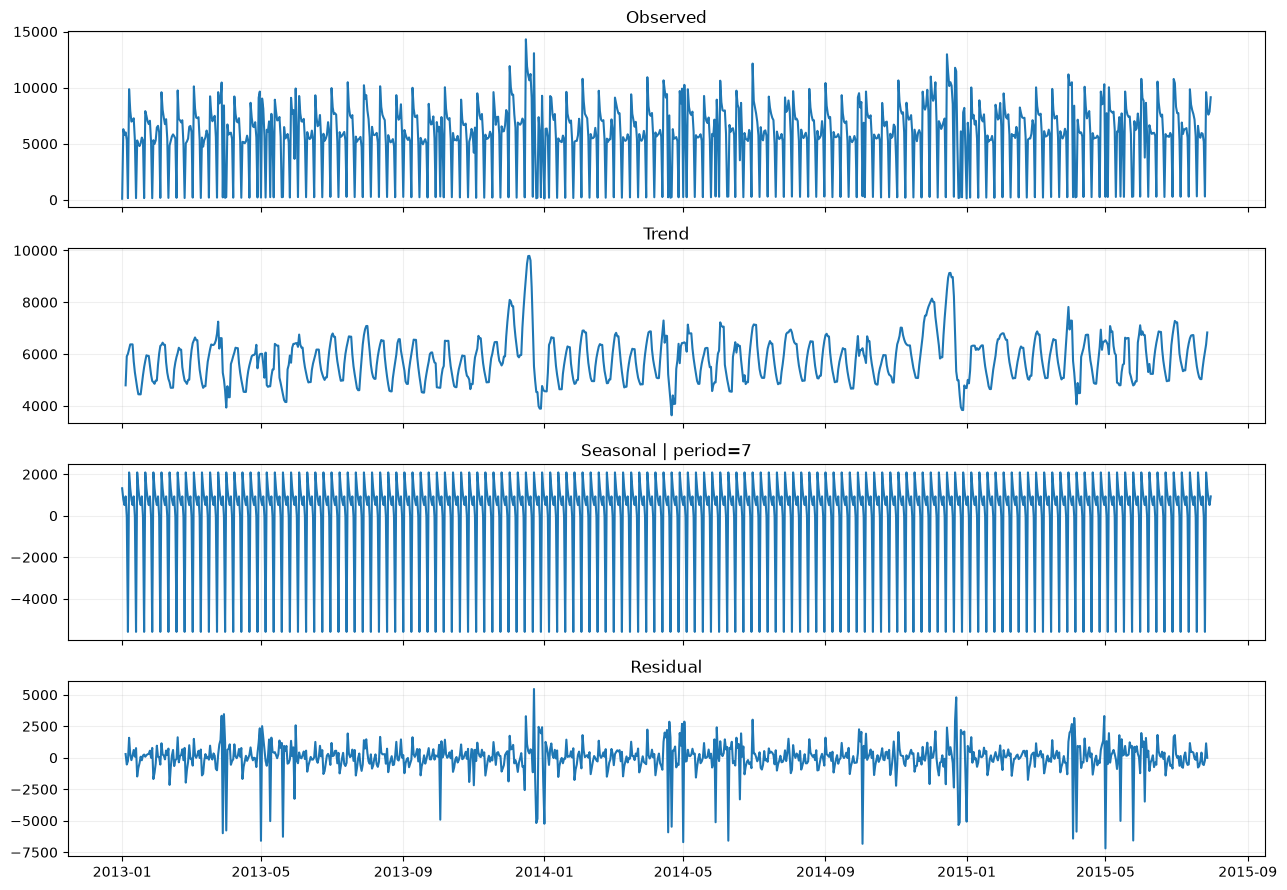

In [54]:
# Dekompozycja średniej sprzedaży z tygodniową sezonowością
DECOMPOSITION_PERIOD = 7

result_7 = run_decomposition(
    daily_avg_sales,
    period=DECOMPOSITION_PERIOD,
)

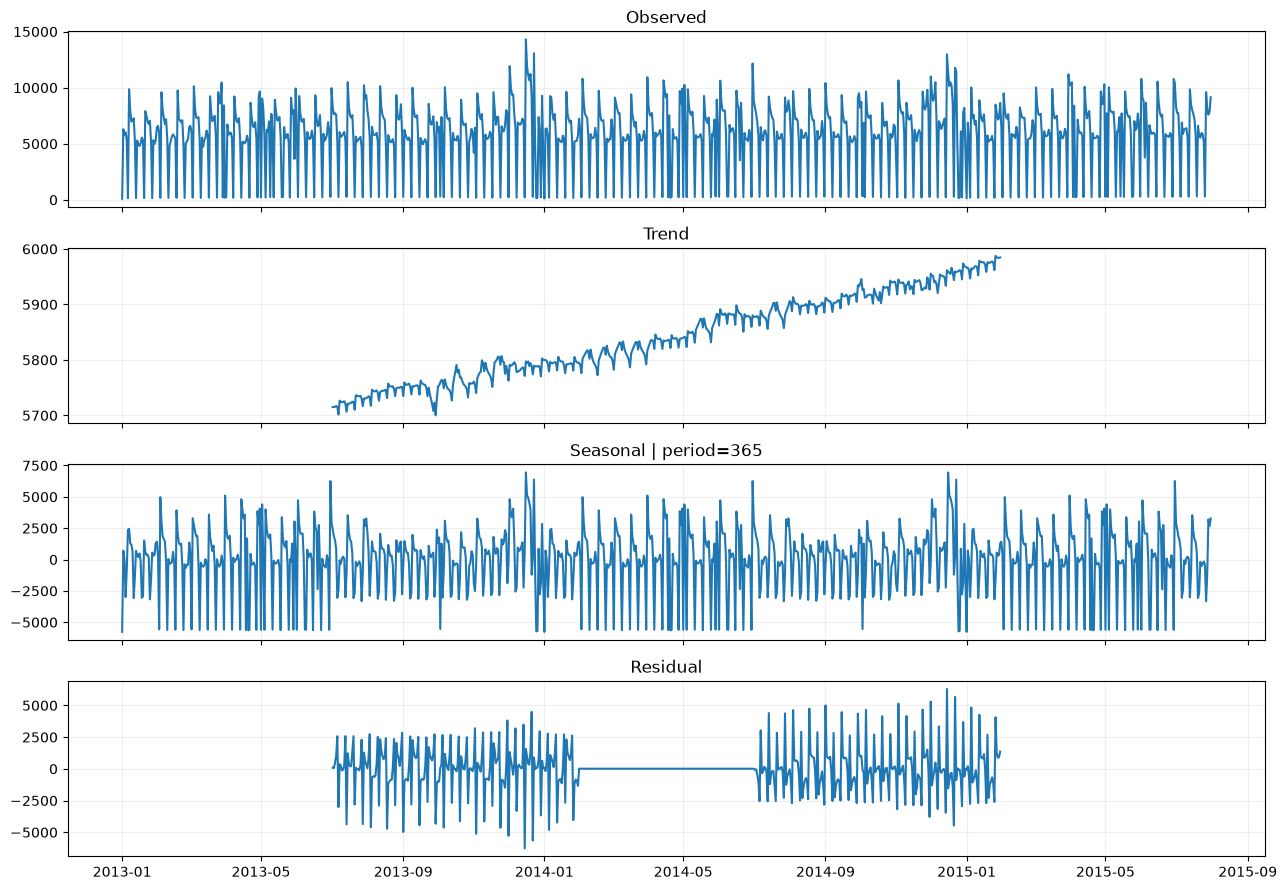

In [55]:
# Dekompozycja średniej sprzedaży z tygodniową sezonowością
DECOMPOSITION_PERIOD = 365

result_7 = run_decomposition(
    daily_avg_sales,
    period=DECOMPOSITION_PERIOD,
)

## Wnioski z analizy średnich kroczących

 Krótkoterminowa dynamika: Sprzedaż charakteryzuje się dużymi wahaniami z dnia na dzień. Występują również pojedyncze skoki sprzedaży oraz gwałtowne spadki.
Średnioterminowa dynamika: Średnia krocząca z 30 dni jest bardziej stabilna i wskazuje, że przeciętny poziom sprzedaży przez większość badanego okresu utrzymuje się na zbliżonym poziomie.
 Długoterminowa dynamika: Średnia krocząca z 90 dni pokazuje względnie stabilny poziom sprzedaży. Nie obserwuje się wyraźnego, długotrwałego trendu wzrostowego ani spadkowego.
 Wpływ długości okna: Im dłuższe okno średniej kroczącej, tym silniejsze wygładzenie krótkoterminowych wahań i wolniejsza reakcja na nagłe zmiany sprzedaży.

Wniosek końcowy: Analiza średnich kroczących wskazuje na znaczną zmienność dziennej sprzedaży przy względnie stabilnym poziomie średnio- i długoterminowym. Średnie kroczące z 7, 30 i 90 dni mogą zostać wykorzystane jako potencjalne cechy w modelu prognostycznym. Podczas ich tworzenia należy jednak uwzględnić wyłącznie wcześniejsze obserwacje, aby uniknąć wycieku informacji (data leakage).

## Wnioski z dekompozycji średniej dziennej sprzedaży

Dekompozycja szeregu czasowego średniej dziennej sprzedaży, przeprowadzona z okresem sezonowości równym 365 dni, pozwoliła wyodrębnić trend, komponent sezonowy oraz składnik resztowy.

1. Sales (dane obserwowane). Szereg charakteryzuje się regularnymi, znacznymi wahaniami sprzedaży oraz pojedynczymi wartościami szczytowymi. Widoczne są powtarzające się okresy bardzo niskiej sprzedaży, co może wskazywać na wpływ dni wolnych od handlu lub dni zamknięcia sklepów.

2. Trend. Zaobserwowano wyraźny trend wzrostowy. Średni poziom sprzedaży zwiększa się w analizowanym okresie, co może świadczyć o wzroście sprzedaży w badanej grupie sklepów. Na trendzie widoczne są również krótkookresowe wahania.

3. Seasonal (sezonowość). Komponent sezonowy wykazuje znaczne i regularne wahania, jednak na wykresie widoczne są także gwałtowne odchylenia. Ponieważ zastosowano okres 365 dni, dekompozycja uwzględnia roczny cykl sezonowy. Nie można jednak jednoznacznie stwierdzić, że wszystkie zaobserwowane wzorce wynikają z sezonowości rocznej — część z nich może być związana z powtarzalnością tygodniową.

4. Residual (składnik resztowy). Składnik resztowy charakteryzuje się dużym rozproszeniem wokół zera oraz występowaniem wartości skrajnych. Oznacza to, że trend i komponent sezonowy nie wyjaśniają w pełni zmienności sprzedaży. Na reszty mogą wpływać m.in. promocje, święta, zdarzenia jednorazowe i inne czynniki nieuwzględnione w dekompozycji.
Podsumowanie

Dekompozycja wskazuje na wzrostowy trend średniej dziennej sprzedaży oraz znaczną zmienność sezonową i nieregularną. Mimo uśrednienia wyników dla wybranych sklepów w szeregu pozostają wyraźne wahania i obserwacje odstające.



##  Stacjonarność, różnicowanie oraz ACF/PACF



In [77]:
def adf_summary(series):
    clean = pd.Series(series).dropna()
    result = adfuller(clean, autolag="AIC")
    return pd.Series({
        "ADF statistic": result[0],
        "p-value": result[1],
        "used_lags": result[2],
        "n_obs": result[3],
    })


def stationarity_experiment(series, diff_order):
    if diff_order not in (0, 1):
        raise ValueError("Dozwolone wartości DIFF_ORDER: 0 lub 1.")

    transformed = series.copy() if diff_order == 0 else series.diff()
    transformed = transformed.dropna()
    summary = adf_summary(transformed)

    fig, axes = plt.subplots(2, 1, figsize=(13, 7))
    axes[0].plot(transformed.index, transformed.values, linewidth=0.8)
    axes[0].set_title(f"TRAIN |Store = {STORE_ID} | DIFF_ORDER={diff_order}")
    axes[0].grid(alpha=0.25)

    plot_acf(transformed, lags=50, ax=axes[1], alpha=0.05)
    axes[1].set_title(f"ACF |Store = {STORE_ID} | DIFF_ORDER={diff_order}")
    axes[1].grid(alpha=0.25)

    plt.tight_layout()
    plt.show()
    display(summary.to_frame("wartość"))
    return transformed, summary

In [82]:
DIFF_ORDER = 1

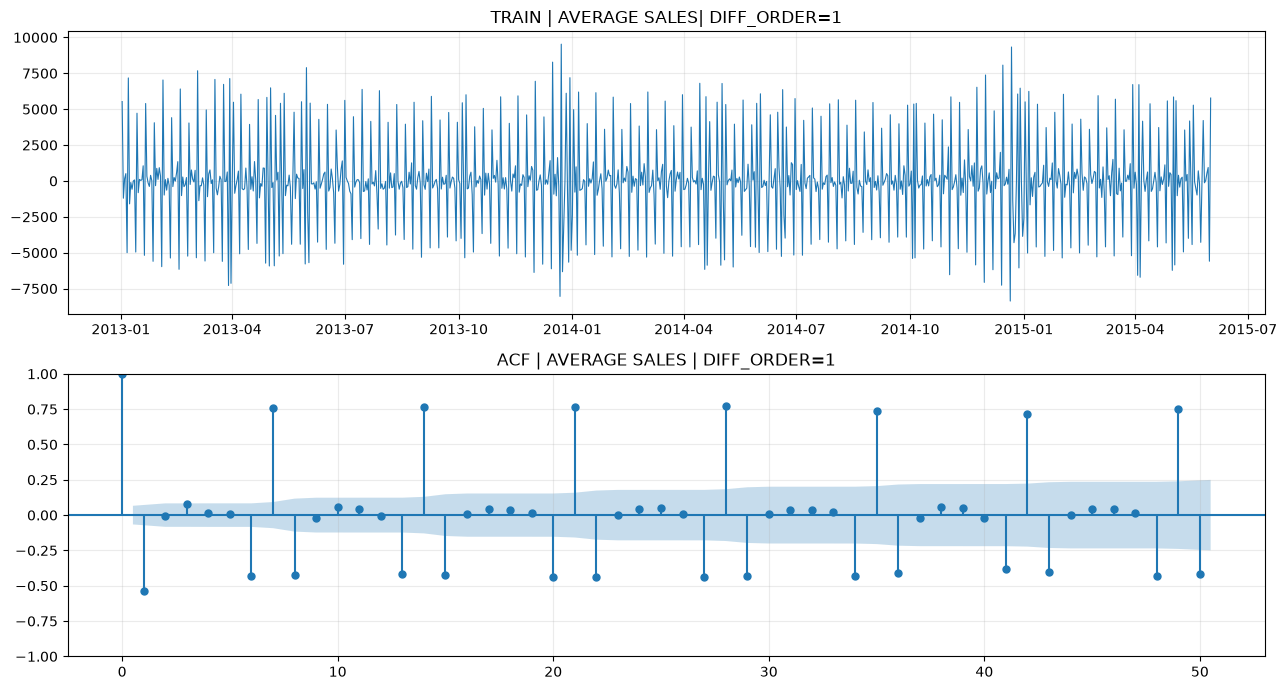

,wartość
ADF statistic,-1.105283e+01
p-value,5.029833e-20
used_lags,2.000000e+01
n_obs,8.600000e+02


In [83]:
stationary_series, adf_result = stationarity_experiment(train_series, DIFF_ORDER)

In [84]:
def adf_summary(series):
    clean = pd.Series(series).dropna()
    result = adfuller(clean, autolag="AIC")
    return pd.Series({
        "ADF statistic": result[0],
        "p-value": result[1],
        "used_lags": result[2],
        "n_obs": result[3],
    })


def stationarity_experiment(series, diff_order):
    if diff_order not in (0, 1):
        raise ValueError("Dozwolone wartości DIFF_ORDER: 0 lub 1.")

    transformed = series.copy() if diff_order == 0 else series.diff()
    transformed = transformed.dropna()
    summary = adf_summary(transformed)

    fig, axes = plt.subplots(2, 1, figsize=(13, 7))
    axes[0].plot(transformed.index, transformed.values, linewidth=0.8)
    axes[0].set_title(f"TRAIN | AVERAGE SALES| DIFF_ORDER={diff_order}")
    axes[0].grid(alpha=0.25)

    plot_acf(transformed, lags=50, ax=axes[1], alpha=0.05)
    axes[1].set_title(f"ACF | AVERAGE SALES | DIFF_ORDER={diff_order}")
    axes[1].grid(alpha=0.25)

    plt.tight_layout()
    plt.show()
    display(summary.to_frame("wartość"))
    return transformed, summary

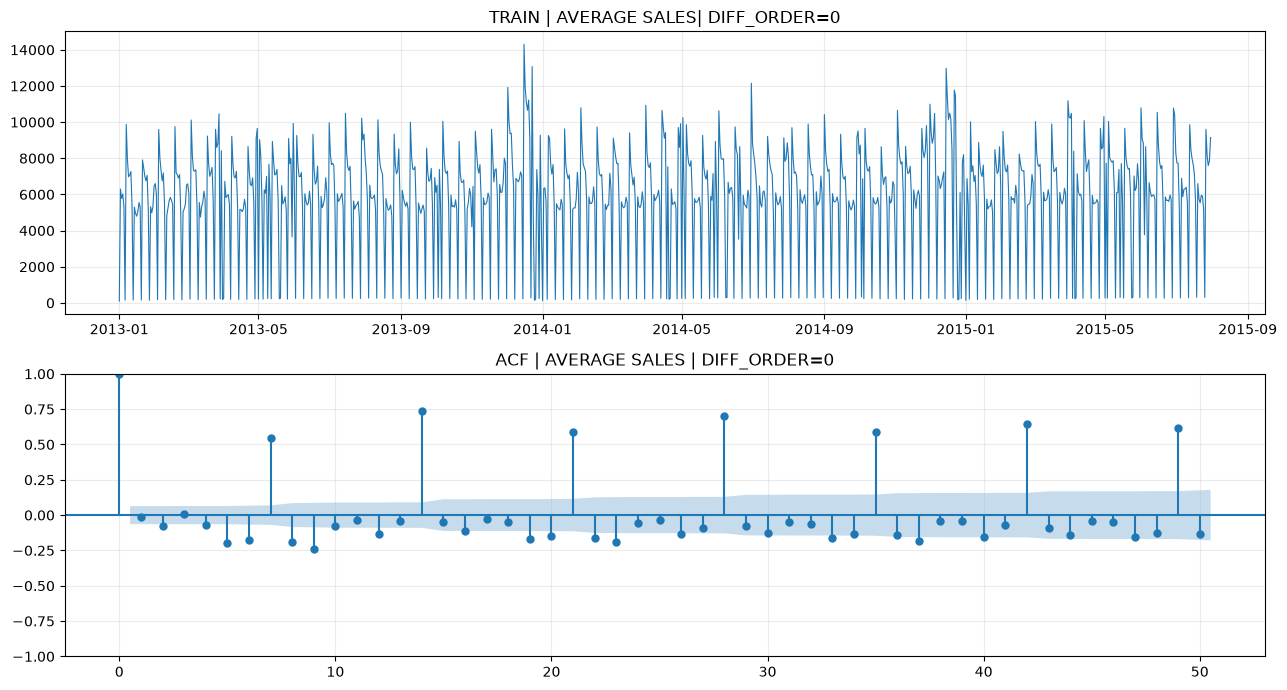

,wartość
ADF statistic,-5.762232e+00
p-value,5.637495e-07
used_lags,2.100000e+01
n_obs,9.200000e+02


In [81]:
stationary_series, adf_result = stationarity_experiment(daily_avg_sales, DIFF_ORDER)

## WNIOSKI Stacjonarność, różnicowanie oraz ACF/PACF

## Pięć foldów expanding-window i diagnostyka leakage

Tworzymy pięć kolejnych 30-dniowych okien walidacyjnych przed końcowym testem. Dla każdego dnia w foldzie prognoza jest one-step-ahead: do predykcji dnia `t` dostępna jest rzeczywista sprzedaż z dnia `t-1`. 

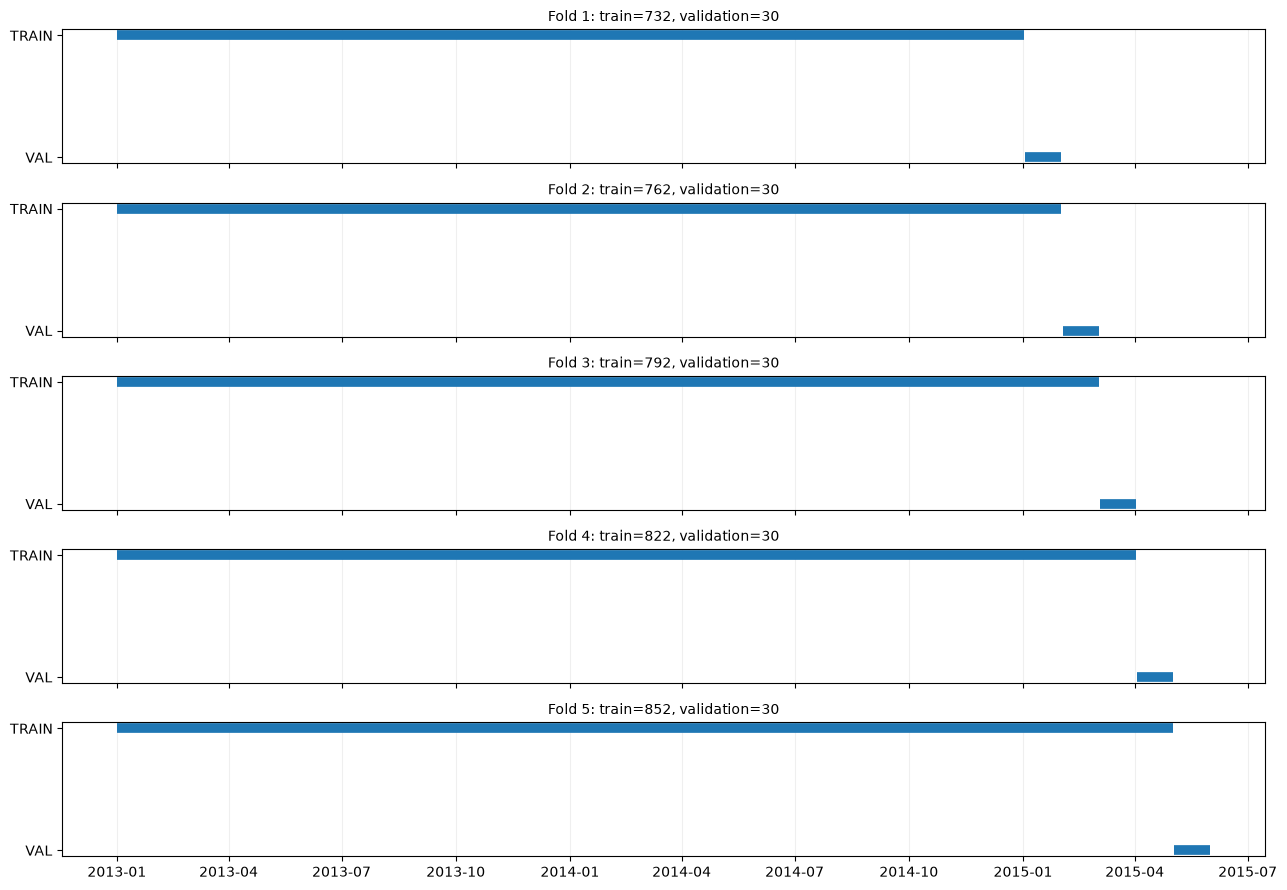

In [94]:
def plot_time_series_splits(series, n_splits=5, horizon=30):
    tscv = TimeSeriesSplit(n_splits=n_splits, test_size=horizon)
    dates = series.index

    fig, axes = plt.subplots(n_splits, 1, figsize=(13, 9), sharex=True)
    axes = np.atleast_1d(axes)

    for fold, (train_idx, val_idx) in enumerate(tscv.split(series), start=1):
        ax = axes[fold - 1]
        ax.hlines(1, dates[train_idx[0]], dates[train_idx[-1]], linewidth=7, label="TRAIN")
        ax.hlines(0, dates[val_idx[0]], dates[val_idx[-1]], linewidth=7, label="VALIDATION")
        ax.set_yticks([0, 1])
        ax.set_yticklabels(["VAL", "TRAIN"])
        ax.set_title(f"Fold {fold}: train={len(train_idx)}, validation={len(val_idx)}", fontsize=10)
        ax.grid(alpha=0.2, axis="x")

    plt.tight_layout()
    plt.show()

plot_time_series_splits(train_series, n_splits=5, horizon=30)

## 7. Baseline: Naive, Seasonal Naive i Moving Average

W przeciwieństwie do prognozy wielokrokowej, dla każdego dnia walidacji używamy rzeczywistych wcześniejszych obserwacji. Naive korzysta z `Sales(t-1)`, Seasonal Naive z `Sales(t-7)`, a Moving Average ze średniej z poprzednich 7 dni. Dni zamknięcia otrzymują prognozę zero.

## War 1 train 

In [117]:
HORIZON = 30
SEASONAL_LAG = 7
MA_WINDOW = 7

BASELINE_CONFIGS = [(7, 7), (365, 30)]


def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
    }


def plot_actual_vs_forecast(actual, predictions, title):
    fig, ax = plt.subplots(figsize=(13, 4.5))
    ax.plot(actual.index, actual.values, linewidth=1.1, label="Rzeczywiste")
    for name, pred in predictions.items():
        pred = pd.Series(pred).reindex(actual.index)
        ax.plot(pred.index, pred.values, linewidth=1.0, alpha=0.85, label=name)
    ax.set_title(title)
    ax.set_xlabel("Data")
    ax.set_ylabel("Sprzedaż")
    ax.legend()
    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()


def evaluate_baselines(history_series, target_dates, seasonal_lag, ma_window):
    target_dates = pd.DatetimeIndex(target_dates)
    actual = history_series.reindex(target_dates)

    predictions = {
        "Naive": history_series.shift(1).reindex(target_dates),
        f"Seasonal Naive (lag={seasonal_lag})": history_series.shift(seasonal_lag).reindex(target_dates),
        f"Moving Average (window={ma_window})": history_series.shift(1).rolling(ma_window).mean().reindex(target_dates),
    }

    rows = []
    for name, pred in predictions.items():
        if pred.isna().any():
            raise ValueError(f"Brak historii potrzebnej do policzenia: {name}")
        metrics = regression_metrics(actual, pred)
        rows.append({"model": name, "MAE": metrics["MAE"], "RMSE": metrics["RMSE"]})

    return pd.DataFrame(rows), actual, predictions


baseline_experiments = {}
REQUIRED_BASELINE_CONFIGS = {(7, 7), (365, 30)}

In [118]:
def record_result(model_name, config, dataset, mae, rmse):
    results = {
        "model": model_name,
        "config": config,
        "dataset": dataset,
        "MAE": mae,
        "RMSE": rmse,
    }

    if "experiment_results" not in globals():
        globals()["experiment_results"] = []

    experiment_results.append(results)


,model,MAE,RMSE
0,Naive,1827.900,2741.414
1,Seasonal Naive (lag=7),1161.767,1520.968
2,Moving Average (window=7),1292.638,1828.032


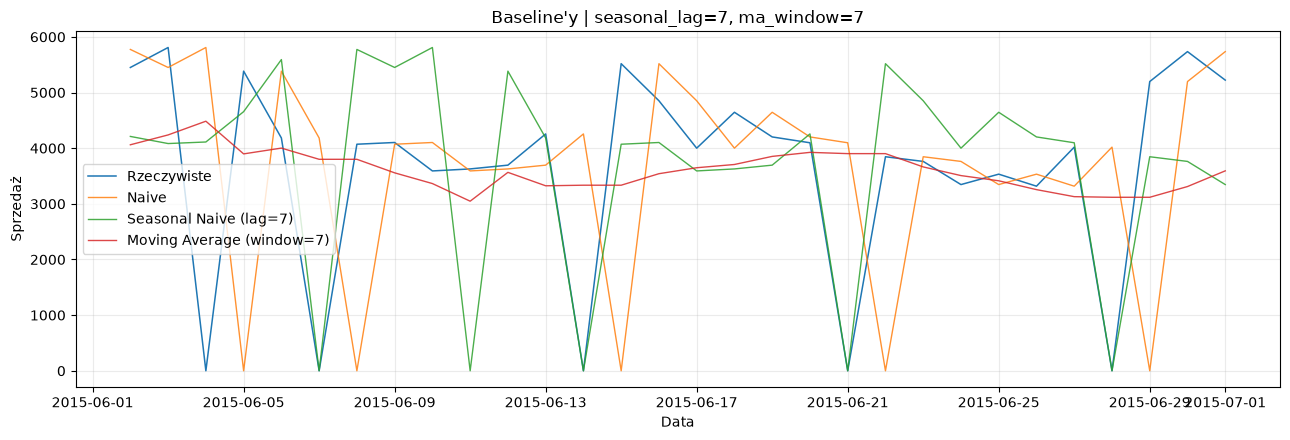

In [119]:
modeling_series = pd.concat([train_series, validation_series]).sort_index()

baseline_table, baseline_actual, baseline_predictions = evaluate_baselines(
    modeling_series,
    validation_series.index,
    seasonal_lag=SEASONAL_LAG,
    ma_window=MA_WINDOW,
)

baseline_key = (SEASONAL_LAG, MA_WINDOW)
baseline_experiments[baseline_key] = {
    "table": baseline_table.copy(),
    "actual": baseline_actual.copy(),
    "predictions": {k: v.copy() for k, v in baseline_predictions.items()},
}

for _, row in baseline_table.iterrows():
    model_name = row["model"]
    if model_name == "Naive":
        config = "lag=1"
    elif model_name.startswith("Seasonal Naive"):
        config = f"lag={SEASONAL_LAG}"
    else:
        config = f"window={MA_WINDOW}"
    record_result(model_name.split(" (")[0], config, "validation", row["MAE"], row["RMSE"])

display(baseline_table.round(3))
plot_actual_vs_forecast(
    baseline_actual,
    baseline_predictions,
    title=f"Baseline'y | seasonal_lag={SEASONAL_LAG}, ma_window={MA_WINDOW}",
)


### Wnioski z porównania modeli bazowych

Przeprowadzony eksperyment wykazał, że spośród pięciu analizowanych wariantów najlepsze wyniki uzyskał model Seasonal Naive z opóźnieniem 7 dni. Model ten osiągnął MAE = 1 161,77 oraz RMSE = 1 520,97, co wskazuje na przewagę tygodniowego wzorca sezonowego nad prognozowaniem opartym wyłącznie na ostatniej obserwacji lub danych sprzed roku.

Modele Moving Average z oknami 7 i 30 dni zapewniły umiarkowanie dobre wyniki, jednak nie przewyższyły modelu Seasonal Naive (lag=7). Wskazuje to, że uwzględnienie sezonowości tygodniowej jest istotne dla jakości prognoz sprzedaży.

Najgorsze wyniki uzyskał Seasonal Naive z opóźnieniem 365 dni. Oznacza to, że w analizowanym okresie dane sprzed roku były mniej przydatne niż obserwacje z poprzedniego tygodnia.

Model Seasonal Naive (lag=7) zostaje przyjęty jako najlepszy baseline do dalszych eksperymentów. W kolejnym etapie należy porównać go z modelami ETS oraz modelami uczenia maszynowego, wykorzystując identyczny schemat walidacji kroczącej i ten sam horyzont prognozy. Wyniki baseline'ów będą punktem odniesienia do oceny, czy bardziej złożone modele rzeczywiście poprawiają jakość prognoz.

In [120]:
# Check whether all models use exactly the same validation dates

target_dates = pd.DatetimeIndex(validation_data.index)

print("Liczba dat walidacyjnych:", len(target_dates))
print("Liczba unikalnych dat:", target_dates.nunique())
print("Pierwsza data:", target_dates.min())
print("Ostatnia data:", target_dates.max())

print("\nLiczba prognoz dla każdego modelu:")
for name, pred in baseline_predictions.items():
    pred = pd.Series(pred).reindex(target_dates)
    print(
        f"{name}: {len(pred)} dat, "
        f"{pred.notna().sum()} prognoz, "
        f"{pred.index.equals(target_dates)}"
    )

Liczba dat walidacyjnych: 30
Liczba unikalnych dat: 30
Pierwsza data: 2015-06-02 00:00:00
Ostatnia data: 2015-07-01 00:00:00

Liczba prognoz dla każdego modelu:
Naive: 30 dat, 30 prognoz, True
Seasonal Naive (lag=7): 30 dat, 30 prognoz, True
Moving Average (window=7): 30 dat, 30 prognoz, True
